# Lab: Concatenate attention for German-to-English translation

**Problem.** A fixed-context long short-term memory (LSTM) encoder–decoder must carry a whole German sentence in its final encoder states. Can a decoder that consults *all* encoder outputs at each English token make better use of the source?

**Learning objectives**

1. Trace source, decoder, score, weight, context, and vocabulary-logit shapes.
2. Implement concatenate attention with a source-padding mask.
3. Implement beam search and compare it with greedy decoding.
4. Compare fixed-context and attention models using perplexity and generated-translation BLEU.
5. Interpret translation errors and attention maps without treating attention as proof of word alignment.

**Prerequisites:** Python, PyTorch embeddings and LSTMs, cross-entropy, teacher forcing, and the companion [concatenate-attention notes](../../seq2seq_learning/concatenate_attn.md) and [LSTM translator](../../seq2seq_learning/Seq2Seq_LSTM.ipynb). The [tweet classifier](../../seq2seq_learning/disaster_tweets_with_attention.ipynb) supplies a sequence-to-one comparison: it makes one attention-based decision, whereas this decoder recomputes attention for every output token.

The core implementation and shape checks fit a two-hour session. The controlled training comparison and written analysis can be finished during the following week. This exercise uses an LSTM as a bridge to attention; it does **not** implement Transformer self-attention.

**Dataset and access.** The full run explicitly downloads [Multi30k Task 1](https://huggingface.co/datasets/bentrevett/multi30k), with German (`de`) and English (`en`) captions and published train/validation/test splits. The [original dataset paper](https://aclanthology.org/W16-3210/) describes the source. The dataset card does not state a license; consult [upstream terms](https://github.com/multi30k/dataset) before redistributing examples. The notebook downloads data into the Hugging Face cache only after you select full-data mode; it does not commit data, weights, or credentials. Download size and GPU runtime vary by cache and machine and have not been measured for this notebook.

**Setup.** Python 3.10+ with `torch`, `datasets`, `matplotlib`, and `sacrebleu`; a GPU is useful for the full comparison. In a hosted notebook, install these in a separate setup cell if absent. The default smoke mode uses only PyTorch and a tiny, **illustrative** in-memory corpus. It verifies execution, not translation quality. Seeds reduce variation but do not guarantee identical GPU results. No paid API is used.

**Files.** Set `DATA_MODE = "multi30k"` and `RUN_FULL_TRAINING = True` deliberately for the full run. Rerunning training starts new models and overwrites files of the same names in `seq2seq_attention_outputs/`. The Hugging Face dataset cache is managed separately. If using Kaggle, enable internet for the first download or attach a local copy and adapt the labeled loading cell.


**Jiwak — completed limited-data CPU comparison.** Real Multi30k training/validation/test splits; 4,000 seeded training pairs, up to 12 epochs, 64-dimensional embeddings and 128-dimensional hidden states. Both models share this configuration; best checkpoints are selected by validation loss. The same seeded 200-example test sample is used for all four metric rows. This is a limited-data experiment, not the original 12,000-pair configuration.


In [1]:
import random
import re
from collections import Counter
from pathlib import Path

import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import Dataset, DataLoader

SEED = 17
random.seed(SEED)
torch.set_num_threads(2)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_MODE = "multi30k"  # Real translation data, limited CPU subset
RUN_FULL_TRAINING = True
MAX_TRAIN_PAIRS = 4000  # use None for all 29,000 training pairs
WORKSPACE_ROOT = next(root for root in (Path.cwd(), *Path.cwd().parents)
                      if (root / "data/multi30k").exists())
OUTPUT_DIR = WORKSPACE_ROOT / "completed_labs/seq2seq_attention_outputs"
TRAIN_EPOCHS = 12

print("PyTorch", torch.__version__, "device", device, "mode", DATA_MODE)


PyTorch 2.11.0+cu130 device cpu mode multi30k


## 1. Data and vocabulary

Multi30k already has separate splits. We sample only from its *training* split, then fit each word vocabulary on those training pairs. A simple Unicode word/punctuation tokenizer keeps this lab focused on attention. It is a teaching preprocessing choice, not a claim that word-level tokenization is best for translation. Unknown words map to `<unk>`. We remove exact normalized source duplicates from validation and test to prevent the same input appearing in two splits; this changes the evaluation set slightly, so report its size.

The small built-in pairs below are illustrative and deliberately insufficient for meaningful translation training. The full run requires a network download on first use. Source and target direction here is **German → English** to match the notes, even though `EncodeDecoderTranslator.ipynb` used English → German.


In [2]:
SMOKE_TRAIN = [
    ("das buch ist rot", "the book is red"),
    ("das auto ist blau", "the car is blue"),
    ("das haus ist grün", "the house is green"),
    ("das boot ist gelb", "the boat is yellow"),
    ("ein mann geht", "a man walks"),
    ("eine frau geht", "a woman walks"),
    ("ein mann läuft", "a man runs"),
    ("eine frau läuft", "a woman runs"),
]
SMOKE_VALID = [("das auto ist rot", "the car is red")]
SMOKE_TEST = [("das buch ist blau", "the book is blue")]

def normalized(text):
    return " ".join(text.lower().split())

def remove_seen_sources(pairs, seen):
    kept = []
    for src, tgt in pairs:
        key = normalized(src)
        if key not in seen:
            kept.append((src, tgt))
            seen.add(key)
    return kept

if DATA_MODE == "smoke":
    train_pairs, valid_pairs, test_pairs = SMOKE_TRAIN, SMOKE_VALID, SMOKE_TEST
elif DATA_MODE == "multi30k":
    # Official Multi30k task-1 files: train, val, test_2016_flickr.
    # Downloaded from https://github.com/multi30k/dataset/tree/master/data/task1/raw
    import gzip
    def read_parallel(split):
        root = WORKSPACE_ROOT / "data/multi30k"
        with gzip.open(root / f"{split}.de.gz", "rt", encoding="utf-8") as f:
            sources = f.read().splitlines()
        with gzip.open(root / f"{split}.en.gz", "rt", encoding="utf-8") as f:
            targets = f.read().splitlines()
        assert len(sources) == len(targets)
        return list(zip(sources, targets))
    train_pairs = read_parallel("train")
    random.Random(SEED).shuffle(train_pairs)
    if MAX_TRAIN_PAIRS is not None:
        train_pairs = train_pairs[:MAX_TRAIN_PAIRS]
    valid_pairs = read_parallel("val")
    test_pairs = read_parallel("test_2016_flickr")
    seen = {normalized(src) for src, _ in train_pairs}
    valid_pairs = remove_seen_sources(valid_pairs, seen)
    test_pairs = remove_seen_sources(test_pairs, seen)
else:
    raise ValueError("DATA_MODE must be 'smoke' or 'multi30k'")

assert train_pairs and valid_pairs and test_pairs
print("train/validation/test pairs:", len(train_pairs), len(valid_pairs), len(test_pairs))
print("example:", train_pairs[0])


train/validation/test pairs: 4000 1014 1000
example: ('Ein Mann spricht mit einer Gruppe von Personen.', 'A man speaking to a group of people.')


In [3]:
SPECIALS = ["<pad>", "<unk>", "<sos>", "<eos>"]
PAD, UNK, SOS, EOS = range(4)

def tokenize(text):
    return re.findall(r"[^\W_]+|[^\w\s]", text.lower(), flags=re.UNICODE)

def build_vocab(texts, min_freq=2, max_size=6000):
    counts = Counter(tok for text in texts for tok in tokenize(text))
    vocab = {tok: idx for idx, tok in enumerate(SPECIALS)}
    for tok, freq in counts.most_common():
        if freq >= min_freq and len(vocab) < max_size:
            vocab[tok] = len(vocab)
    return vocab

min_freq = 1 if DATA_MODE == "smoke" else 2
src_vocab = build_vocab((src for src, _ in train_pairs), min_freq)
tgt_vocab = build_vocab((tgt for _, tgt in train_pairs), min_freq)
tgt_itos = {idx: tok for tok, idx in tgt_vocab.items()}
print("German/English vocabulary sizes:", len(src_vocab), len(tgt_vocab))

class PairDataset(Dataset):
    def __init__(self, pairs):
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        src, tgt = self.pairs[index]
        src_ids = [SOS] + [src_vocab.get(t, UNK) for t in tokenize(src)] + [EOS]
        tgt_ids = [SOS] + [tgt_vocab.get(t, UNK) for t in tokenize(tgt)] + [EOS]
        return torch.tensor(src_ids), torch.tensor(tgt_ids)

def collate(batch):
    srcs, tgts = zip(*batch)
    lengths = torch.tensor([len(s) for s in srcs], dtype=torch.long)
    src = nn.utils.rnn.pad_sequence(srcs, batch_first=True, padding_value=PAD)
    tgt = nn.utils.rnn.pad_sequence(tgts, batch_first=True, padding_value=PAD)
    return src, lengths, tgt

batch_size = 2 if DATA_MODE == "smoke" else 64
train_loader = DataLoader(PairDataset(train_pairs), batch_size=batch_size, shuffle=True, collate_fn=collate,
                          generator=torch.Generator().manual_seed(SEED))
valid_loader = DataLoader(PairDataset(valid_pairs), batch_size=batch_size, collate_fn=collate)
src_batch, lengths, tgt_batch = next(iter(train_loader))
print("source", tuple(src_batch.shape), "lengths", tuple(lengths.shape), "target", tuple(tgt_batch.shape))


German/English vocabulary sizes: 2197 2064
source (64, 29) lengths (64,) target (64, 27)


## 2. Fixed-context baseline

The encoder returns `outputs` of shape $(B,T_x,H)$ and final `(hidden, cell)` states of shape $(L,B,H)$. Packing lets the LSTM ignore padded source time steps. The baseline decoder uses only the final states, so the encoder outputs are computed but not consulted during generation. We use the **same encoder** in the attention model later.

The output projection produces one logit per English vocabulary item. `CrossEntropyLoss` applies log-softmax internally; its padding index excludes padded *target* positions. This target-loss mask does not replace the source-attention mask.


In [4]:
EMB_DIM = 64  # CPU comparison: same embedding width for both models
HIDDEN_DIM = 128  # CPU comparison: same hidden width for both models

class Encoder(nn.Module):
    def __init__(self, input_dim, emb_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(input_dim, emb_dim, padding_idx=PAD)
        self.lstm = nn.LSTM(emb_dim, hidden_dim, batch_first=True)

    def forward(self, src, lengths):
        embedded = self.embedding(src)
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        packed_outputs, (hidden, cell) = self.lstm(packed)
        outputs, _ = pad_packed_sequence(packed_outputs, batch_first=True, total_length=src.size(1))
        return outputs, (hidden, cell)

class Decoder(nn.Module):
    def __init__(self, output_dim, emb_dim, hidden_dim, attention=None):
        super().__init__()
        self.embedding = nn.Embedding(output_dim, emb_dim, padding_idx=PAD)
        self.attention = attention
        context_dim = hidden_dim if attention is not None else 0
        self.lstm = nn.LSTM(emb_dim + context_dim, hidden_dim, batch_first=True)
        self.fc_out = nn.Linear(hidden_dim + context_dim, output_dim)

    def forward(self, previous_token, hidden, cell, encoder_outputs, src_mask):
        embedded = self.embedding(previous_token).unsqueeze(1)  # (B,1,E)
        weights = None
        if self.attention is not None:
            context, weights = self.attention(hidden[-1], encoder_outputs, src_mask)
            lstm_input = torch.cat((embedded, context.unsqueeze(1)), dim=-1)
        else:
            context = None
            lstm_input = embedded
        output, (hidden, cell) = self.lstm(lstm_input, (hidden, cell))
        output = output.squeeze(1)
        if context is not None:
            output = torch.cat((output, context), dim=-1)
        logits = self.fc_out(output)
        return logits, hidden, cell, weights

class Seq2Seq(nn.Module):
    def __init__(self, src_vocab_size, tgt_vocab_size, attention=None):
        super().__init__()
        self.encoder = Encoder(src_vocab_size, EMB_DIM, HIDDEN_DIM)
        self.decoder = Decoder(tgt_vocab_size, EMB_DIM, HIDDEN_DIM, attention)

    def forward(self, src, lengths, tgt, teacher_forcing_ratio=0.5):
        encoder_outputs, (hidden, cell) = self.encoder(src, lengths)
        src_mask = src.ne(PAD)
        previous = tgt[:, 0]  # <sos>, never the current target token
        all_logits = []
        for t in range(1, tgt.size(1)):
            logits, hidden, cell, _ = self.decoder(previous, hidden, cell, encoder_outputs, src_mask)
            all_logits.append(logits)
            previous = tgt[:, t] if random.random() < teacher_forcing_ratio else logits.argmax(-1)
        return torch.stack(all_logits, dim=1)  # (B,T_y-1,V_y)

def make_model(with_attention=False):
    attention = ConcatAttention(HIDDEN_DIM) if with_attention else None
    return Seq2Seq(len(src_vocab), len(tgt_vocab), attention).to(device)

criterion = nn.CrossEntropyLoss(ignore_index=PAD)
baseline = make_model()
src_d, len_d, tgt_d = (x.to(device) for x in (src_batch, lengths, tgt_batch))
with torch.no_grad():
    demo_logits = baseline(src_d, len_d, tgt_d, teacher_forcing_ratio=1.0)
print("baseline logits", tuple(demo_logits.shape))
assert demo_logits.shape == (len(src_batch), tgt_batch.size(1)-1, len(tgt_vocab))


baseline logits (64, 26, 2064)


### Exercise 1 — trace the computation

For batch size $B=3$, padded source length $T_x=12$, target length $T_y=9$ including `<sos>`, hidden width $H=256$, and target vocabulary size $V_y=4000$, give the shapes of encoder outputs, the top decoder hidden state, attention scores, attention weights, context, and training logits. Explain why the target at step $t$ cannot be supplied as the decoder input at that same step.


## 3. Concatenate attention

At target step $t$, the **previous** decoder hidden state $s_{t-1}$ is the query. For each valid source position $i$, compute

$$e_{t,i}=v_a^\top\tanh(W_a[s_{t-1};h_i]+b_a),\qquad
\alpha_{t,:}=\operatorname{softmax}(e_{t,:}),\qquad
r_t=\sum_i\alpha_{t,i}h_i.$$

`[s;h_i]` has $2H$ features. `W_a` projects to $H$ alignment features, and `v_a` produces one scalar score. The same scoring layers are shared across source positions and output steps. Mask padding **before** softmax using a very negative score, so padded positions get zero probability. For any row, at least `<sos>` and `<eos>` are valid, so softmax always has a valid position.

### Exercise 2 — implement and check attention

Complete `ConcatAttention.forward`. Return `(context, weights)`. Set `ATTENTION_READY = True` after implementing it, then run the checks. Do not detach the context or weights: gradients must reach the scoring layers and encoder.


In [5]:
class ConcatAttention(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.alignment = nn.Linear(2 * hidden_dim, hidden_dim)
        self.score = nn.Linear(hidden_dim, 1, bias=False)

    def forward(self, query, encoder_outputs, src_mask):
        # query: (B, H), encoder_outputs: (B, Tx, H), src_mask: (B, Tx) bool
        B, Tx, H = encoder_outputs.shape
        # Repeat query over source positions
        query_expanded = query.unsqueeze(1).expand(-1, Tx, -1)  # (B, Tx, H)
        # Concatenate query and encoder outputs
        combined = torch.cat((query_expanded, encoder_outputs), dim=-1)  # (B, Tx, 2H)
        # Score through alignment layer and score vector
        energy = self.score(torch.tanh(self.alignment(combined)))  # (B, Tx, 1)
        energy = energy.squeeze(-1)  # (B, Tx)
        # Mask padding before softmax with very negative score
        energy = energy.masked_fill(~src_mask, float('-inf'))
        # Softmax over source positions
        weights = torch.softmax(energy, dim=-1)  # (B, Tx)
        # Weighted sum of encoder outputs to get context vector
        context = torch.bmm(weights.unsqueeze(1), encoder_outputs).squeeze(1)  # (B, H)
        return context, weights

ATTENTION_READY = True

In [6]:
if ATTENTION_READY:
    torch.manual_seed(SEED)
    attention_model = make_model(with_attention=True)
    source_outputs, (hidden, cell) = attention_model.encoder(src_d, len_d)
    mask = src_d.ne(PAD)
    context, weights = attention_model.decoder.attention(hidden[-1], source_outputs, mask)
    assert weights.shape == src_d.shape
    assert context.shape == (src_d.size(0), HIDDEN_DIM)
    assert torch.allclose(weights.sum(dim=1), torch.ones(src_d.size(0), device=device), atol=1e-5)
    assert torch.all(weights[~mask] < 1e-6)
    logits = attention_model(src_d, len_d, tgt_d, teacher_forcing_ratio=1.0)
    loss = criterion(logits.reshape(-1, len(tgt_vocab)), tgt_d[:, 1:].reshape(-1))
    loss.backward()
    assert attention_model.decoder.attention.alignment.weight.grad is not None
    assert attention_model.decoder.attention.score.weight.grad is not None
    assert attention_model.encoder.lstm.weight_ih_l0.grad is not None
    print("attention shapes, mask, and gradient checks passed; loss", round(loss.item(), 3))
else:
    print("Exercise 2 pending: baseline remains runnable; set ATTENTION_READY=True after implementation")


attention shapes, mask, and gradient checks passed; loss 7.638


## 4. Training and autoregressive inference

Training minimizes the mean negative log probability of the correct English tokens, excluding target `<pad>`:

$$\mathcal L=-\frac{1}{N}\sum_{b,t:\,y_{b,t}\ne\texttt{<pad>}}\log p(y_{b,t}\mid y_{b,<t},X_b).$$

The model returns raw logits; `CrossEntropyLoss(ignore_index=PAD)` implements this reduction over the $N$ nonpadding tokens. Training uses 50% teacher forcing. Validation loss uses reference *previous* tokens (100% teacher forcing) to measure reference-token probability. Translation evaluation below uses **zero** reference tokens after `<sos>`. These are different evaluation conditions and must be labeled accordingly.

The default code runs two optimization batches as a smoke check. To compare translation quality, use Multi30k mode and enable the full run. The two models use the same split, tokenizer, vocabulary, hidden size, batch size, epoch limit, optimizer, greedy decoding, and random seed. Attention adds parameters, so parameter counts should be reported rather than treated as identical models.


In [7]:
def run_epoch(model, loader, optimizer=None, max_batches=None):
    training = optimizer is not None
    model.train(training)
    total_loss, total_tokens = 0.0, 0
    for batch_index, (src, lengths, tgt) in enumerate(loader):
        if max_batches is not None and batch_index >= max_batches:
            break
        src, lengths, tgt = src.to(device), lengths.to(device), tgt.to(device)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits = model(src, lengths, tgt, 0.5 if training else 1.0)
            gold = tgt[:, 1:]
            loss = criterion(logits.reshape(-1, logits.size(-1)), gold.reshape(-1))
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
        n = gold.ne(PAD).sum().item()
        total_loss += loss.item() * n
        total_tokens += n
    return total_loss / max(total_tokens, 1)

def greedy_translate(model, source_text, max_steps=40):
    model.eval()
    src_ids = [SOS] + [src_vocab.get(t, UNK) for t in tokenize(source_text)] + [EOS]
    src = torch.tensor(src_ids, device=device).unsqueeze(0)
    lengths = torch.tensor([len(src_ids)], device=device)
    generated, rows = [], []
    with torch.no_grad():
        encoder_outputs, (hidden, cell) = model.encoder(src, lengths)
        previous = torch.tensor([SOS], device=device)
        for _ in range(max_steps):
            logits, hidden, cell, weights = model.decoder(
                previous, hidden, cell, encoder_outputs, src.ne(PAD)
            )
            previous = logits.argmax(dim=-1)
            token_id = previous.item()
            if token_id == EOS:
                break
            generated.append(tgt_itos.get(token_id, "<unk>"))
            if weights is not None:
                rows.append(weights[0].cpu())
    attention_map = torch.stack(rows) if rows else None
    return generated, attention_map

smoke_optimizer = torch.optim.Adam(baseline.parameters(), lr=1e-3)
smoke_loss = run_epoch(baseline, train_loader, smoke_optimizer, max_batches=2)
print("baseline two-batch smoke loss:", round(smoke_loss, 3))
print("smoke translation (not a quality result):", greedy_translate(baseline, valid_pairs[0][0])[0])
if ATTENTION_READY:
    smoke_attention_optimizer = torch.optim.Adam(attention_model.parameters(), lr=1e-3)
    print("attention two-batch smoke loss:", round(run_epoch(attention_model, train_loader, smoke_attention_optimizer, max_batches=2), 3))


baseline two-batch smoke loss: 7.609
smoke translation (not a quality result): ['a', 'info', 'man', 'info', 'of', 'her', 'bird', 'bowling', 'younger', 'canopy', 'kissing', 'fields', 'machinery', 'under', 'foot', 'being', 'free', 'jumping', 'bright', 'messy', 'juggling', 'violin', 'younger', 'kissing', 'product', 'night', 'younger', 'kissing', 'kissing', 'foot', 'relaxes', 'foot', 'filled', 'without', 'bridge', 'cup', 'walkers', 'free', 'bird', 'button']
attention two-batch smoke loss: 7.628


### Exercise 3 — controlled comparison

Set `DATA_MODE = "multi30k"`, restart the kernel, run the notebook, set `ATTENTION_READY = True`, then enable `RUN_FULL_TRAINING`. Inspect both validation-loss curves. If you alter the subset size or epoch limit, record the change. A few smoke batches do not establish convergence or an attention benefit. Run the full comparison when compute permits; a smaller CPU run is acceptable if clearly labeled as a smoke or limited-data experiment.


baseline epoch 1: train 5.714, valid 4.763
baseline epoch 2: train 4.812, valid 4.505
baseline epoch 3: train 4.648, valid 4.367
baseline epoch 4: train 4.543, valid 4.239
baseline epoch 5: train 4.464, valid 4.145
baseline epoch 6: train 4.375, valid 4.036
baseline epoch 7: train 4.307, valid 3.961
baseline epoch 8: train 4.216, valid 3.868
baseline epoch 9: train 4.174, valid 3.803
baseline epoch 10: train 4.115, valid 3.762
baseline epoch 11: train 4.071, valid 3.699
baseline epoch 12: train 4.025, valid 3.656
attention epoch 1: train 5.600, valid 4.662
attention epoch 2: train 4.695, valid 4.355
attention epoch 3: train 4.459, valid 4.111
attention epoch 4: train 4.265, valid 3.926
attention epoch 5: train 4.106, valid 3.795
attention epoch 6: train 3.955, valid 3.662
attention epoch 7: train 3.834, valid 3.569
attention epoch 8: train 3.685, valid 3.456
attention epoch 9: train 3.578, valid 3.374
attention epoch 10: train 3.469, valid 3.300
attention epoch 11: train 3.356, valid 3

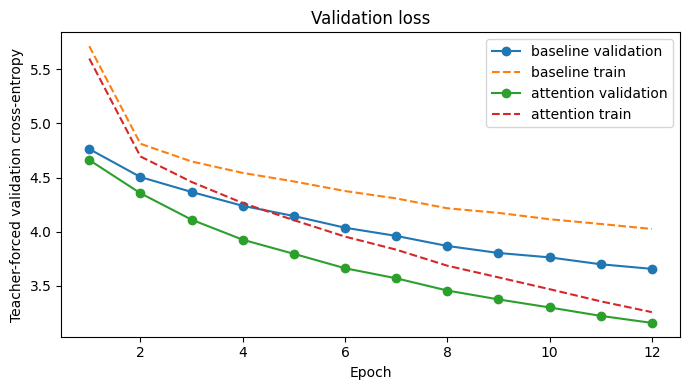

In [8]:
def train_model(with_attention, epochs=TRAIN_EPOCHS):
    torch.manual_seed(SEED)
    random.seed(SEED)
    train_loader.generator.manual_seed(SEED)
    model = make_model(with_attention)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = []
    best_loss, best_state, stale = float("inf"), None, 0
    for epoch in range(1, epochs + 1):
        train_loss = run_epoch(model, train_loader, optimizer)
        valid_loss = run_epoch(model, valid_loader)
        history.append((train_loss, valid_loss))
        print(f"{'attention' if with_attention else 'baseline'} epoch {epoch}: train {train_loss:.3f}, valid {valid_loss:.3f}")
        if valid_loss < best_loss:
            best_loss = valid_loss
            best_state = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
            stale = 0
        else:
            stale += 1
            if stale >= 3:
                break
    model.load_state_dict(best_state)
    return model, history

if RUN_FULL_TRAINING:
    assert DATA_MODE == "multi30k", "Use the full dataset for a quality comparison"
    assert ATTENTION_READY, "Implement Exercise 2 first"
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    baseline, baseline_history = train_model(False)
    attention_model, attention_history = train_model(True)
    torch.save(baseline.state_dict(), OUTPUT_DIR / "baseline.pt")
    torch.save(attention_model.state_dict(), OUTPUT_DIR / "attention.pt")
    print("parameters:", sum(p.numel() for p in baseline.parameters()), sum(p.numel() for p in attention_model.parameters()))
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(7, 4))
    for name, history in [("baseline", baseline_history), ("attention", attention_history)]:
        ax.plot(range(1, len(history)+1), [row[1] for row in history], marker="o", label=f"{name} validation")
        ax.plot(range(1, len(history)+1), [row[0] for row in history], linestyle="--", label=f"{name} train")
    ax.set(xlabel="Epoch", ylabel="Teacher-forced validation cross-entropy", title="Validation loss")
    ax.legend()
    fig.tight_layout()
    plt.show()
else:
    print("Full training skipped. Set both switches deliberately for the week-long comparison.")


## 5. Beam-search inference

Greedy decoding keeps one prefix and chooses the highest-probability next token. Beam search keeps `beam_width` prefixes, expands each by candidate next tokens, and retains the best partial sequences. The cumulative score is the **sum of log probabilities**; a length penalty prevents raw sums from always favoring short outputs. Stop expanding a hypothesis once it emits `<eos>`. Every hypothesis must carry its *own* decoder hidden and cell states. The encoder outputs remain fixed for one input sentence.

### Exercise 4 — implement beam search

Implement `beam_translate` for one sentence. Use beam width 3, a maximum of 40 generated tokens, and length-penalty exponent $0.6$. Validate the implementation by checking that width 1 produces the same tokens as greedy decoding under the same limit. Set `BEAM_READY = True` after implementing it. What could cause beam search to choose a different complete sentence even though greedy selected the locally best token at every step?


In [9]:
def beam_translate(model, source_text, beam_width=3, max_steps=40, length_alpha=0.6):
    model.eval()
    src_ids = [SOS] + [src_vocab.get(t, UNK) for t in tokenize(source_text)] + [EOS]
    src = torch.tensor(src_ids, device=device).unsqueeze(0)
    lengths = torch.tensor([len(src_ids)], device=device)

    with torch.no_grad():
        encoder_outputs, (hidden, cell) = model.encoder(src, lengths)
        src_mask = src.ne(PAD)

        # Each beam: (token_ids, log_score, hidden, cell, ended)
        beams = [([SOS], 0.0, hidden, cell, False)]

        def score_fn(beam):
            token_ids, log_score, _, _, _ = beam
            length = len(token_ids) - 1  # exclude SOS
            penalty = ((5 + length) / 6) ** length_alpha
            return log_score / penalty

        for step in range(max_steps):
            candidates = []
            for token_ids, log_score, h, c, ended in beams:
                if ended:
                    candidates.append((token_ids, log_score, h, c, True))
                    continue
                previous = torch.tensor([token_ids[-1]], device=device)
                logits, new_h, new_c, _ = model.decoder(
                    previous, h, c, encoder_outputs, src_mask
                )
                log_probs = torch.log_softmax(logits, dim=-1)
                topk_log_probs, topk_ids = log_probs[0].topk(beam_width)
                for i in range(beam_width):
                    new_id = topk_ids[i].item()
                    new_score = log_score + topk_log_probs[i].item()
                    new_tokens = token_ids + [new_id]
                    is_ended = (new_id == EOS)
                    candidates.append((new_tokens, new_score, new_h, new_c, is_ended))

            candidates.sort(key=score_fn, reverse=True)
            beams = candidates[:beam_width]

            if all(ended for _, _, _, _, ended in beams):
                break

        # Select best beam by length-normalized score
        best = max(beams, key=score_fn)
        result_ids = best[0]

        # Remove SOS and terminal EOS before returning tokens
        tokens = []
        for tid in result_ids:
            if tid == SOS:
                continue
            if tid == EOS:
                break
            tokens.append(tgt_itos.get(tid, "<unk>"))
        return tokens

BEAM_READY = True

In [10]:
if BEAM_READY:
    for checked_model in [baseline] + ([attention_model] if ATTENTION_READY else []):
        for source, _ in valid_pairs[:20]:
            greedy_tokens, _ = greedy_translate(checked_model, source, max_steps=40)
            beam_one = beam_translate(checked_model, source, beam_width=1, max_steps=40)
            assert beam_one == greedy_tokens, (greedy_tokens, beam_one)
    print("Beam width 1 matches greedy on 20 validation sentences for both trained models.")
else:
    print("Exercise 4 pending: beam search has not been tested.")


Beam width 1 matches greedy on 20 validation sentences for both trained models.


## 6. Perplexity and generated translation evaluation

**Perplexity** is $\exp(\text{mean reference-token cross-entropy})$. It measures how much probability the model assigns to held-out reference tokens when previous reference tokens are supplied. It is a property of the **model and test set**, so changing greedy to beam decoding does not change it. **Corpus BLEU** compares generated translations with references and *can* change with decoding. BLEU depends on tokenization and the available references; neither metric alone establishes translation usefulness. We also show exact match as a strict diagnostic.

Use the same seeded sample of `TEST_EVAL_LIMIT` held-out examples for all metrics and both models, with a 40-token decoding cap. `sacrebleu` tokenizes the already space-separated output according to its default English BLEU tokenizer. The training vocabulary was fitted without the test set. Choose settings on validation before using test results.

### Exercise 5 — compare models, decoders, and metrics

Report test perplexity for both models, then BLEU for greedy and beam decoding for each model. Explain why a model can have lower perplexity yet lower BLEU, and why greedy versus beam can change BLEU but not perplexity. Show at least three test examples: one short, one longer, and one failure. Explain whether the evidence supports a benefit from attention **in your run**. If your models have similar scores, say so.


In [11]:
import math

TEST_EVAL_LIMIT = 200  # set to None to use the whole held-out test split

def evaluate_generations(model, pairs, method="greedy"):
    from sacrebleu.metrics import BLEU  # needed only for full evaluation
    hypotheses, references = [], []
    for source, reference in pairs:
        if method == "greedy":
            tokens, _ = greedy_translate(model, source, max_steps=40)
        elif method == "beam":
            tokens = beam_translate(model, source, beam_width=3, max_steps=40, length_alpha=0.6)
        else:
            raise ValueError("method must be greedy or beam")
        hypotheses.append(" ".join(tokens))
        references.append(" ".join(tokenize(reference)))
    bleu = BLEU().corpus_score(hypotheses, [references]).score
    exact = sum(h == r for h, r in zip(hypotheses, references)) / len(pairs)
    return {"BLEU": bleu, "exact_match": exact}, hypotheses, references

if RUN_FULL_TRAINING:
    assert BEAM_READY, "Complete Exercise 4 before test evaluation"
    evaluation_pairs = test_pairs if TEST_EVAL_LIMIT is None else random.Random(SEED).sample(
        test_pairs, min(TEST_EVAL_LIMIT, len(test_pairs))
    )
    evaluation_loader = DataLoader(PairDataset(evaluation_pairs), batch_size=batch_size, collate_fn=collate)
    results, generated = {}, {}
    for name, model in [("baseline", baseline), ("attention", attention_model)]:
        cross_entropy = run_epoch(model, evaluation_loader)
        perplexity = math.exp(cross_entropy)
        for method in ["greedy", "beam"]:
            scores, hypotheses, references = evaluate_generations(model, evaluation_pairs, method)
            results[(name, method)] = {"perplexity": perplexity, **scores}
            generated[(name, method)] = hypotheses
            print(name, method, results[(name, method)])
    print("Held-out examples evaluated:", len(evaluation_pairs))
    attention_outputs = generated[("attention", "greedy")]
    short_index = min(range(len(evaluation_pairs)), key=lambda i: len(tokenize(evaluation_pairs[i][0])))
    long_index = max(range(len(evaluation_pairs)), key=lambda i: len(tokenize(evaluation_pairs[i][0])))
    failed_index = next((i for i, output in enumerate(attention_outputs) if output != references[i]), None)
    example_indices = dict.fromkeys(i for i in [short_index, long_index, failed_index] if i is not None)
    print("Examples: short, long, and first attention exact-match failure where available")
    for index in example_indices:
        print("\nGerman:", evaluation_pairs[index][0])
        print("English reference:", references[index])
        for name in ["baseline", "attention"]:
            for method in ["greedy", "beam"]:
                print(name, method, generated[(name, method)][index])
else:
    print("Test evaluation waits for the full training run.")

if RUN_FULL_TRAINING:
    import pandas as pd
    metrics_table = pd.DataFrame([
        {"model": name, "decoder": method, **scores}
        for (name, method), scores in results.items()
    ])
    print("\nFour-row comparison (same held-out sample):")
    print(metrics_table.to_string(index=False))
    display(metrics_table)


baseline greedy {'perplexity': 38.53839974178554, 'BLEU': 2.796971704035401, 'exact_match': 0.0}
baseline beam {'perplexity': 38.53839974178554, 'BLEU': 2.9380506937076794, 'exact_match': 0.0}
attention greedy {'perplexity': 23.195469994067345, 'BLEU': 8.16249280741698, 'exact_match': 0.0}
attention beam {'perplexity': 23.195469994067345, 'BLEU': 9.108721057319359, 'exact_match': 0.0}
Held-out examples evaluated: 200
Examples: short, long, and first attention exact-match failure where available

German: Ein Armeeoffizier inspiziert etwas.
English reference: an army officer is inspecting something .
baseline greedy a <unk> <unk> <unk> <unk> .
baseline beam a group of people are <unk> .
attention greedy a <unk> <unk> <unk> <unk> <unk> .
attention beam a <unk> <unk> <unk> <unk> <unk> .

German: Ein hell gekleideter Mann fotografiert eine Gruppe von Männern in dunklen Anzügen und mit Hüten, die um eine Frau in einem trägerlosen Kleid herum stehen.
English reference: a man in light colored 

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


,model,decoder,perplexity,BLEU,exact_match
0,baseline,greedy,38.53840,2.796972,0.0
1,baseline,beam,38.53840,2.938051,0.0
2,attention,greedy,23.19547,8.162493,0.0
3,attention,beam,23.19547,9.108721,0.0


## 7. Attention map and interpretation

The plot has **English generated tokens on rows** and **German source tokens on columns**, including `<sos>` and `<eos>` in the source. Each row sums to one. A high weight marks a representation the decoder used strongly at that step; it is not proof of a causal explanation or a one-to-one linguistic alignment.

### Exercise 6 — inspect the mechanism

For one successful and one failed translation, describe where attention concentrates when generating a noun and another token. Compare this repeated decoder-step attention with the tweet classifier's single sequence-level attention calculation. Discuss at least one limitation of interpreting the map.


relative success (highest sentence BLEU; not exact match) source: Ein Mann in einem schwarzen Hemd und Jeans steht auf dem Gehsteig und blickt in die Kamera.
Reference: A man in a black shirt and jeans standing on the sidewalk looking at the camera.
Generated: a man in a black shirt and jeans and a black camera and the camera .
  a              -> source[5]=schwarzen (0.355)
  man            -> source[3]=in (0.312)
  in             -> source[5]=schwarzen (0.647)
  a              -> source[5]=schwarzen (0.496)
  black          -> source[6]=hemd (0.716)
  shirt          -> source[6]=hemd (0.756)
  and            -> source[9]=steht (0.543)
  jeans          -> source[9]=steht (0.517)
  and            -> source[11]=dem (0.365)
  a              -> source[18]=. (0.701)
  black          -> source[18]=. (0.602)
  camera         -> source[18]=. (0.956)
  and            -> source[18]=. (0.996)
  the            -> source[18]=. (0.971)
  camera         -> source[18]=. (0.992)
  .              -> so

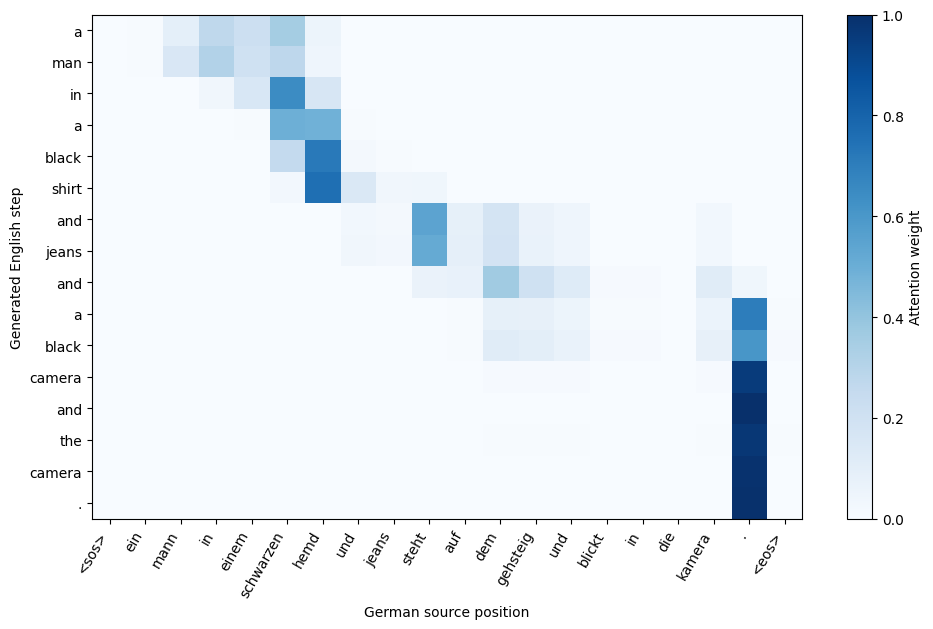

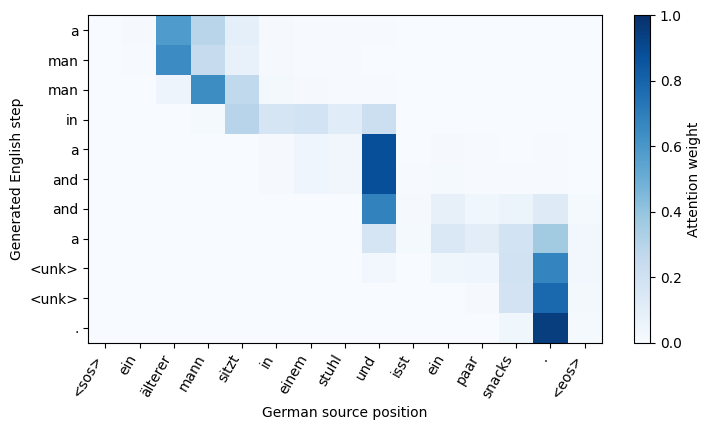

In [12]:
def plot_attention(model, source_text):
    import matplotlib.pyplot as plt
    tokens, matrix = greedy_translate(model, source_text)
    if matrix is None:
        print("No attention map; use the attention model and produce at least one token.")
        return
    source_tokens = ["<sos>"] + tokenize(source_text) + ["<eos>"]
    fig, ax = plt.subplots(figsize=(max(7, len(source_tokens)*0.5), max(3, len(tokens)*0.4)))
    im = ax.imshow(matrix.numpy(), aspect="auto", vmin=0, vmax=1, cmap="Blues")
    ax.set_xticks(range(len(source_tokens)), source_tokens, rotation=60, ha="right")
    ax.set_yticks(range(len(tokens)), tokens)
    ax.set_xlabel("German source position")
    ax.set_ylabel("Generated English step")
    fig.colorbar(im, ax=ax, label="Attention weight")
    fig.tight_layout()
    plt.show()

if RUN_FULL_TRAINING:
    from sacrebleu.metrics import BLEU
    sentence_bleu = BLEU(effective_order=True)
    success_index = next((i for i, output in enumerate(attention_outputs)
                          if output == references[i]), None)
    if success_index is None:
        # Explicitly report a relative success, never pretend it is exact.
        success_index = max(range(len(evaluation_pairs)), key=lambda i:
            sentence_bleu.sentence_score(attention_outputs[i], [references[i]]).score)
        success_label = "relative success (highest sentence BLEU; not exact match)"
    else:
        success_label = "exact-match success"
    failure_index = next(i for i, output in enumerate(attention_outputs) if output != references[i])
    map_evidence = []
    for label, index in [(success_label, success_index), ("failure", failure_index)]:
        source, reference = evaluation_pairs[index]
        output_tokens, matrix = greedy_translate(attention_model, source)
        source_tokens = ["<sos>"] + tokenize(source) + ["<eos>"]
        print(label, "source:", source)
        print("Reference:", reference)
        print("Generated:", " ".join(output_tokens))
        peaks = []
        if matrix is not None:
            for token, row in zip(output_tokens, matrix):
                j = int(row.argmax())
                peaks.append({"target": token, "source": source_tokens[j],
                              "source_position": j, "weight": float(row[j])})
                print(f"  {token:14s} -> source[{j}]={source_tokens[j]} ({float(row[j]):.3f})")
        map_evidence.append({"label": label, "index": index, "source": source,
                             "reference": reference, "generated": output_tokens, "peaks": peaks})
        plot_attention(attention_model, source)
    import json
    evidence = {
        "config": {"seed": SEED, "data_mode": DATA_MODE, "train_pairs": len(train_pairs),
                   "valid_pairs": len(valid_pairs), "test_pairs": len(test_pairs),
                   "evaluation_pairs": len(evaluation_pairs), "max_epochs": TRAIN_EPOCHS,
                   "embedding_dim": EMB_DIM, "hidden_dim": HIDDEN_DIM,
                   "src_vocab": len(src_vocab), "tgt_vocab": len(tgt_vocab)},
        "parameters": {"baseline": sum(p.numel() for p in baseline.parameters()),
                       "attention": sum(p.numel() for p in attention_model.parameters())},
        "histories": {"baseline": baseline_history, "attention": attention_history},
        "metrics": metrics_table.to_dict(orient="records"),
        "examples": [{"index": i, "source": evaluation_pairs[i][0],
                      "reference": references[i],
                      "outputs": {f"{name}_{method}": generated[(name, method)][i]
                                  for name in ("baseline", "attention") for method in ("greedy", "beam")}}
                     for i in example_indices],
        "attention_maps": map_evidence,
    }
    (WORKSPACE_ROOT / "completed_labs/lab4_results.json").write_text(json.dumps(evidence, indent=2))
    (OUTPUT_DIR / "vocabulary_and_config.json").write_text(json.dumps(
        {"source_vocab": src_vocab, "target_vocab": tgt_vocab, "config": evidence["config"]}, indent=2))
else:
    print("Attention plotting waits for a trained attention model.")


## Deliverables and review

Submit the completed student notebook with: (1) attention and beam-search implementations plus checks; (2) configuration, training curves, and parameter counts; (3) a four-row baseline/attention × greedy/beam table with perplexity and BLEU; (4) three translated examples and two attention maps; (5) short answers to Exercises 1, 4, 5, and 6, including a failure analysis. Keep downloaded data and checkpoints out of the submission unless specifically requested. Do not claim that a smoke run establishes quality.

**Practice rubric (20 marks):** correct attention and source-padding mask 6; beam search and width-one check 3; controlled training plus perplexity/BLEU comparison 6; translation and attention-map interpretation 3; reproducibility and clear submission 2. Partial credit: correct shapes, masking, and decoding logic can earn credit even when full GPU training is incomplete, provided the limitation is stated.

**Further reading:** [Bahdanau, Cho, and Bengio (2015)](https://arxiv.org/abs/1409.0473) on neural machine translation with alignment; [Multi30k dataset paper](https://aclanthology.org/W16-3210/); [PyTorch packed sequences](https://pytorch.org/docs/stable/generated/torch.nn.utils.rnn.pack_padded_sequence.html). The lab's concatenate scorer follows the course notes; it is a pedagogical implementation rather than a reproduction of published translation results.


## Written answers

### Exercise 1 — Shape trace

For `B=3`, `T_x=12`, `T_y=9`, `H=256`, and `V_y=4000`, encoder outputs are `(3, 12, 256)`, the top decoder hidden state is `(3, 256)`, attention scores and weights are each `(3, 12)`, context is `(3, 256)`, and teacher-forced training logits are `(3, 8, 4000)`. At step `t`, the decoder receives the previous target token to predict the current one; feeding the current gold token would leak the answer into its own prediction.

### Exercise 4 — Beam search

Beam search can return a different complete sentence because it ranks cumulative sequence log-probabilities (with a length penalty), rather than committing to the single locally highest-probability token at every step. A slightly weaker first token can lead to a stronger complete sequence later.

### Exercise 3 — controlled training and scope

The run used 4,000 seeded Multi30k training pairs, 1,014 validation pairs after source-overlap filtering, and a seeded sample of 200 from 1,000 test pairs. Source and target vocabularies were learned only from training text (2,197 and 2,064 entries). Both models used 64-dimensional embeddings, 128 hidden units, batch size 64, Adam at 0.001, teacher forcing 0.5 in training, gradient clipping at 1.0, and seed 17. Each trained for 12 epochs; the checkpoint with lowest teacher-forced validation loss was restored. The batch-order generator and model seed were reset separately for each run.

Baseline validation cross-entropy decreased from 4.763 to 3.656; attention decreased from 4.662 to 3.157. The plots show train and validation histories. Training uses partial teacher forcing, whereas validation uses full reference prefixes, so their loss levels are not directly comparable evidence of overfitting. Baseline has 737,616 parameters and attention 1,100,368: attention adds 362,752 parameters. Therefore this comparison controls data and training settings but does not isolate attention from increased capacity. The two-batch checks earlier in the notebook are implementation checks; all results below come from the fresh trained models, not those smoke checks.

### Exercise 5 — model comparison, decoding, and examples

| Model | Decoder | Test perplexity | Corpus BLEU | Exact match |
|---|---|---:|---:|---:|
| baseline | greedy | 38.538 | 2.797 | 0.0% |
| baseline | beam | 38.538 | 2.938 | 0.0% |
| attention | greedy | 23.195 | 8.162 | 0.0% |
| attention | beam | 23.195 | 9.109 | 0.0% |

All four rows use the same 200 test pairs. Perplexity is the exponential of teacher-forced reference-token cross-entropy, ignoring target padding. It is unchanged by greedy versus beam decoding because neither the model nor the reference-conditioned probability calculation changes. BLEU scores generated text, so changing the search algorithm can change it. In this run beam width 3 improves baseline BLEU from 2.797 to 2.938 and attention BLEU from 8.162 to 9.109. Width 1 matches greedy on 20 validation sentences for each trained model.

Perplexity and BLEU can disagree: probability assigned under correct reference prefixes does not capture errors after a model generates its own mistaken prefix, and BLEU rewards overlapping token sequences rather than calibrated probabilities. Here they agree on a benefit for attention: lower perplexity (23.195 vs 38.538) and higher BLEU for both decoders. Absolute scores remain low; this is limited-data evidence, not a reliable translation system.

**Short example:** `Ein Armeeoffizier inspiziert etwas.` has reference `an army officer is inspecting something .`. Baseline greedy produces `a <unk> <unk> <unk> <unk> .`; attention greedy produces `a <unk> <unk> <unk> <unk> <unk> .`. Baseline beam invents `a group of people are <unk> .`. Both systems struggle with uncommon vocabulary, and beam search cannot restore words absent from the learned vocabulary. The aggregate attention improvement does not imply an improvement on every sentence.

**Long example:** The sentence beginning `Ein hell gekleideter Mann fotografiert eine Gruppe ...` describes a lightly dressed man photographing men in dark suits and hats around a woman in a strapless gown. Baseline greedy starts `a man in a black shirt is a a ...` and then repeats articles. Attention retains more phrase structure but also repeats `in a <unk>`; beam produces `a man in a man is standing ...` rather than preserving the photographer and people. Long-distance content and generation stability remain poor in both models.

**Failure example:** For `Ein älterer Mann sitzt in einem Stuhl und isst ein paar Snacks.`, the reference is `an elderly man sitting in a chair , eating some snacks .`. Attention greedy generates `a man man in a and and a <unk> <unk> .`; beam gives `a man man is sitting on a <unk> of a <unk> .`. Beam recovers `is sitting` but the age, chair and eating/snacks details remain lost, with a repeated `man`. Baseline also repeats generic articles. These examples explain why an improved corpus score still coexists with obvious failures.

### Exercise 6 — two measured attention maps

There were **no exact-reference matches in the 200 test examples for either model/decoder**. Consequently the first map is explicitly a **relative success**, chosen by highest sentence BLEU in the evaluated sample, rather than claimed as a correct translation. This is a diagnostic selection after evaluation and was not used to choose model settings. The second map is a failure.

For the relative success, the source begins `Ein Mann in einem schwarzen Hemd und Jeans ...` and ends `blickt in die Kamera.`. The output correctly starts `a man in a black shirt and jeans`, but later invents and repeats camera-related phrasing. When generating the noun **shirt**, the largest weight is on **hemd** (0.756), a plausible translation association. For the adjective **black**, it also peaks on **hemd** (0.716), rather than solely `schwarzen`; the encoder state summarizes context around the shirt. Later, **camera** peaks on source punctuation `.` (0.956), and subsequent steps put almost all mass there. Correct early content is therefore followed by degenerate attention and decoding; this map is not a clean word alignment.

For the failure about an older man eating snacks, the first **man** peaks on **älterer** (0.648), and the repeated **man** peaks on **mann** (0.642). The generated **and** peaks on **und** (0.880), while **in** peaks on **sitzt** (0.295), a diffuse and linguistically imperfect association. The decoder skips the chair and food details and shifts to punctuation: its two `<unk>` steps peak on `.` at 0.672 and 0.779. This is consistent with losing the remaining sentence content, but the map alone does not establish the cause of the errors.

The translation decoder recomputes attention over the source at each generated target step, conditioned on its current decoder state. The tweet classifier instead reduces a source sequence with one sequence-level attention distribution for a classification decision. Each translation map row is normalized over valid source positions; encoder representations contain context, so a high weight need not point at a literal word-to-word counterpart or identify a causal explanation. A useful follow-up would compare multiple seeds and larger training subsets, report unknown-token rates and length-stratified quality, and use controlled source interventions before making causal claims about attention.
